# Projet Deep Learning : Reconnaissance de panneaux de signalisation

---
## Partie 1 — Recherche, compréhension et préparation des données

### 1.1 Choix du jeu de données (Dataset)
Pour ce projet, nous avons choisi le jeu de données public **GTSRB** (*German Traffic Sign Recognition Benchmark*) parce que c'était celui qui était recommandé et que sa taille est adaptée à l'objectif du projet. Les images sont au format .ppm (Portable Pixmap) et sont en couleur (RGB, 3 canaux, valeurs de 0 à 255 par canal).Source : https://benchmark.ini.rub.de/


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

print("Imports effectues avec succes !")


Imports effectues avec succes !


In [2]:
DATA_DIR = "data"
TRAIN_DIR = os.path.join(DATA_DIR, "GTSRB", "Final_Training", "Images")
TEST_DIR = os.path.join(DATA_DIR, "GTSRB", "Final_Test", "Images")
TEST_CSV = os.path.join(DATA_DIR, "GT-final_test.csv")

# Dictionnaire des 43 classes en francais
classes = {
    0: "Limitation 20 km/h",
    1: "Limitation 30 km/h",
    2: "Limitation 50 km/h",
    3: "Limitation 60 km/h",
    4: "Limitation 70 km/h",
    5: "Limitation 80 km/h",
    6: "Fin limitation 80 km/h",
    7: "Limitation 100 km/h",
    8: "Limitation 120 km/h",
    9: "Depassement interdit",
    10: "Depassement interdit camions",
    11: "Priorite intersection",
    12: "Route prioritaire",
    13: "Cedez le passage",
    14: "STOP",
    15: "Circulation interdite",
    16: "Interdit aux camions",
    17: "Sens interdit",
    18: "Danger general",
    19: "Virage dangereux gauche",
    20: "Virage dangereux droite",
    21: "Succession de virages",
    22: "Cassis / dos d'ane",
    23: "Chaussee glissante",
    24: "Chaussee retrecie",
    25: "Travaux",
    26: "Feux tricolores",
    27: "Passage pietons",
    28: "Passage enfants",
    29: "Cyclistes",
    30: "Verglas / neige",
    31: "Animaux sauvages",
    32: "Fin de toutes interdictions",
    33: "Direction obligatoire droite",
    34: "Direction obligatoire gauche",
    35: "Direction obligatoire tout droit",
    36: "Tout droit ou droite",
    37: "Tout droit ou gauche",
    38: "Contournement droite",
    39: "Contournement gauche",
    40: "Rond-point",
    41: "Fin interdiction depassement",
    42: "Fin interdiction depassement camions"
}

print(f"Nombre total de classes definies : {len(classes)}")


Nombre total de classes definies : 43


### 1.2 Exploration des données

In [3]:
# Comptage du nombre d'images d'entrainement par classe
counts = {}
for c in range(43):
    folder = os.path.join(TRAIN_DIR, f"{c:05d}")
    if os.path.exists(folder):
        counts[c] = len([f for f in os.listdir(folder) if f.endswith('.ppm')])

total_train = sum(counts.values())
df_test = pd.read_csv(TEST_CSV, sep=';')
total_test = len(df_test)

print(f"Nombre total d'images de train : {total_train}")
print(f"Nombre total d'images de test  : {total_test}")
print(f"Nombre total d'images au total : {total_train + total_test}")

# Dimensions des images brutes avant redimensionnement
print(f"Largeur min : {df_test['Width'].min()} px | max : {df_test['Width'].max()} px | moyenne : {df_test['Width'].mean():.1f} px")
print(f"Hauteur min : {df_test['Height'].min()} px | max : {df_test['Height'].max()} px | moyenne : {df_test['Height'].mean():.1f} px")


Nombre total d'images de train : 39209
Nombre total d'images de test  : 12630
Nombre total d'images au total : 51839
Largeur min : 25 px | max : 266 px | moyenne : 50.5 px
Hauteur min : 25 px | max : 232 px | moyenne : 50.4 px


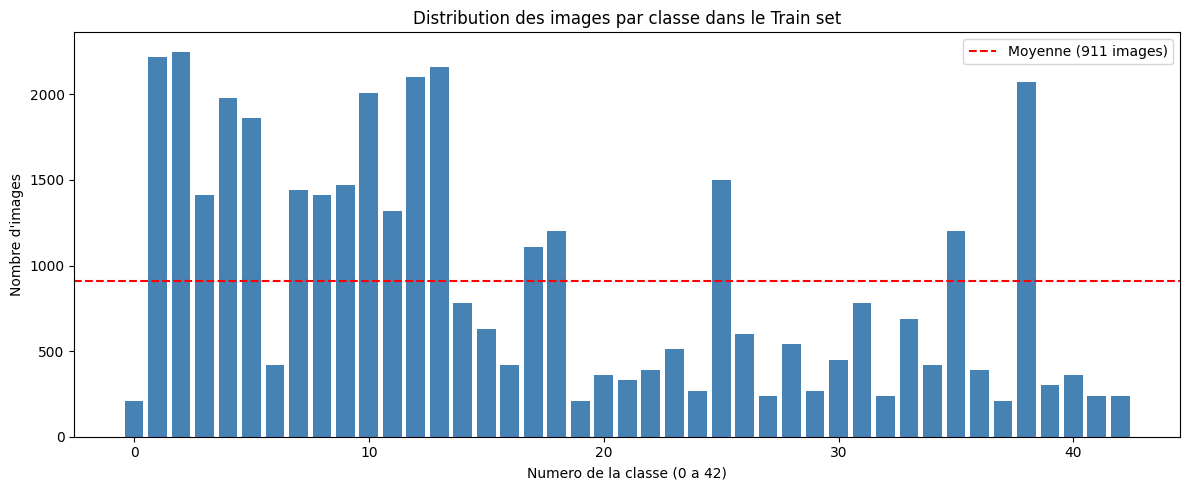

Classe la plus frequente : Classe 2 (Limitation 50 km/h) avec 2250 images
Classe la plus rare      : Classe 0 (Limitation 20 km/h) avec 210 images


In [4]:
# Graphique de la repartition des images par classe
plt.figure(figsize=(12, 5))
plt.bar(counts.keys(), counts.values(), color='steelblue')
plt.axhline(np.mean(list(counts.values())), color='red', linestyle='--', label=f'Moyenne ({int(np.mean(list(counts.values())))} images)')
plt.xlabel("Numero de la classe (0 a 42)")
plt.ylabel("Nombre d'images")
plt.title("Distribution des images par classe dans le Train set")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Classe la plus frequente : Classe {max(counts, key=counts.get)} ({classes[max(counts, key=counts.get)]}) avec {max(counts.values())} images")
print(f"Classe la plus rare      : Classe {min(counts, key=counts.get)} ({classes[min(counts, key=counts.get)]}) avec {min(counts.values())} images")


**Constat sur le déséquilibre des classes :**
On observe un déséquilibre important (ratio de 1 à 10) :
- Certaines classes très fréquentes ont plus de 2 000 images (ex: limitation 50 km/h).
- D'autres classes ont à peine 200 images (ex: limitation 20 km/h ou fin d'interdiction).

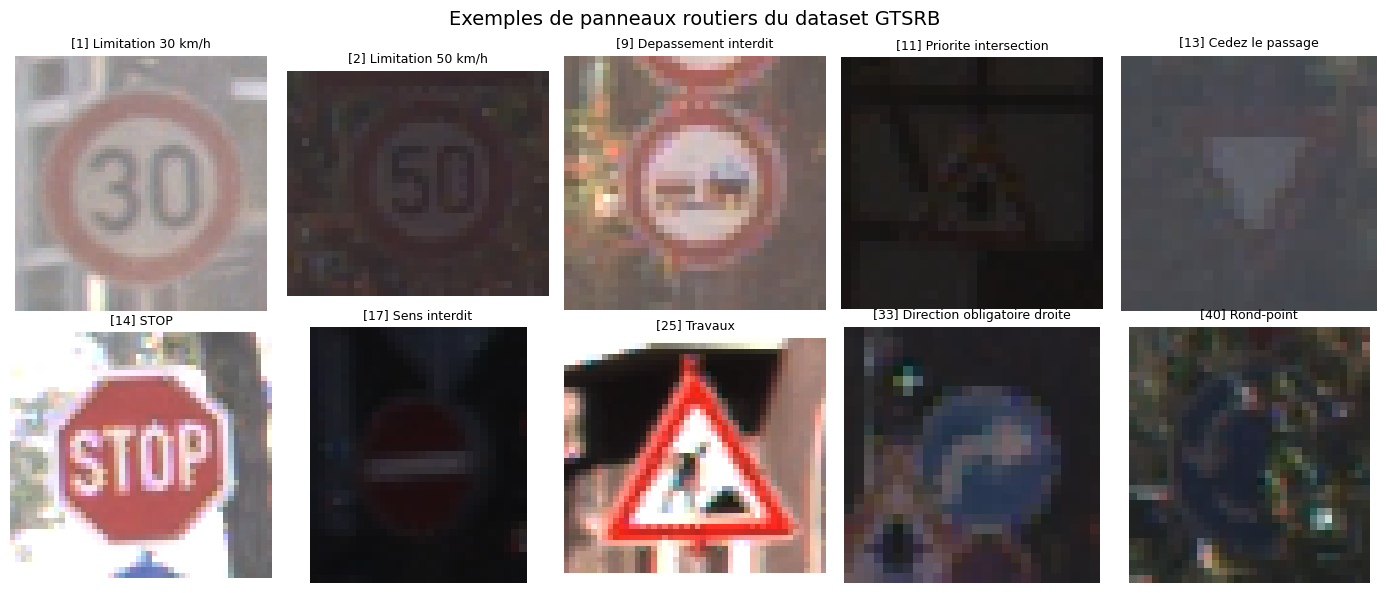

In [5]:
# Affichage d'un echantillon representatif de quelques panneaux
sample_classes = [1, 2, 9, 11, 13, 14, 17, 25, 33, 40]

plt.figure(figsize=(14, 6))
for i, c in enumerate(sample_classes):
    folder = os.path.join(TRAIN_DIR, f"{c:05d}")
    sample_file = [f for f in os.listdir(folder) if f.endswith('.ppm')][0]
    img = cv2.imread(os.path.join(folder, sample_file))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f"[{c}] {classes[c]}", fontsize=9)
    plt.axis('off')

plt.suptitle("Exemples de panneaux routiers du dataset GTSRB", fontsize=14)
plt.tight_layout()
plt.show()


### 1.3 Préparation des données pour le réseau

Avant d'entraîner le modèle, nous appliquons 4 étapes de prétraitement :
1. **Redimensionnement uniforme (32x32) :** les images brutes ont des tailles très variées (de 15x15 à 250x250 pixels). On les redimensionne toutes en 32x32x3 pixels pour avoir une taille d'entrée fixe.
2. **Normalisation des pixels ([0, 1]) :** on divise par 255.0 pour ramener les pixels entre 0.0 et 1.0. Ramener les pixels entre 0 et 1 évite que les calculs explosent et aide le réseau à apprendre plus vite.
3. **Découpage Train / Validation (80% / 20%) :**
   - On sépare le train en 80% train et 20% validation. le train sert à apprendre les poids, la validation sert à surveiller le surapprentissage.
   - Le test set officiel (12 630 images) est strictement mis de côté pour l'évaluation finale.
4. **Encodage One-Hot des labels :** pour une classification à 43 classes avec sortie Softmax et `categorical_crossentropy`.


In [6]:
# Chargement et pretraitement des donnees
npz_file = os.path.join(DATA_DIR, "gtsrb_32x32.npz")

if os.path.exists(npz_file):
    print("Chargement rapide depuis le cache gtsrb_32x32.npz...")
    data = np.load(npz_file)
    X_train_raw = data['X_train']
    y_train_raw = data['y_train']
    X_val_raw   = data['X_val']
    y_val_raw   = data['y_val']
    X_test_raw  = data['X_test']
    y_test_raw  = data['y_test']
else:
    print("Pretraitement des images brutes (redimensionnement en 32x32)...")
    images, labels = [], []
    for c in range(43):
        folder = os.path.join(TRAIN_DIR, f"{c:05d}")
        for fname in os.listdir(folder):
            if fname.endswith('.ppm'):
                img = cv2.imread(os.path.join(folder, fname))
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (32, 32))
                images.append(img)
                labels.append(c)
    images = np.array(images, dtype=np.uint8)
    labels = np.array(labels, dtype=np.int64)

    # Decoupage Train / Validation stratifie (80% / 20%)
    X_train_raw, X_val_raw, y_train_raw, y_val_raw = train_test_split(
        images, labels, test_size=0.20, random_state=42, stratify=labels
    )

    # Test
    test_imgs, test_lbls = [], []
    for _, row in df_test.iterrows():
        img = cv2.imread(os.path.join(TEST_DIR, row['Filename']))
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (32, 32))
            test_imgs.append(img)
            test_lbls.append(row['ClassId'])
    X_test_raw = np.array(test_imgs, dtype=np.uint8)
    y_test_raw = np.array(test_lbls, dtype=np.int64)

# Normalisation des intensites de pixels dans [0.0, 1.0]
X_train = X_train_raw.astype('float32') / 255.0
X_val   = X_val_raw.astype('float32') / 255.0
X_test  = X_test_raw.astype('float32') / 255.0

# Encodage One-Hot des labels pour 43 classes
y_train = to_categorical(y_train_raw, 43)
y_val   = to_categorical(y_val_raw, 43)
y_test  = to_categorical(y_test_raw, 43)

print("Pretraitement termine avec succes !")


Chargement rapide depuis le cache gtsrb_32x32.npz...


Pretraitement termine avec succes !


In [7]:
# Verification des dimensions et des valeurs (comme dans le TP MNIST)
print(f"Dimensions de X_train : {X_train.shape}")
print(f"Dimensions de y_train : {y_train.shape}")
print(f"Dimensions de X_val   : {X_val.shape}")
print(f"Dimensions de y_val   : {y_val.shape}")
print(f"Dimensions de X_test  : {X_test.shape}")
print(f"Dimensions de y_test  : {y_test.shape}")
print(f"Dimensions d'une image : {X_train.shape[1:]}")
print(f"Valeur minimale des pixels : {X_train.min()}")
print(f"Valeur maximale des pixels : {X_train.max()}")


Dimensions de X_train : (31367, 32, 32, 3)
Dimensions de y_train : (31367, 43)
Dimensions de X_val   : (7842, 32, 32, 3)
Dimensions de y_val   : (7842, 43)
Dimensions de X_test  : (12630, 32, 32, 3)
Dimensions de y_test  : (12630, 43)
Dimensions d'une image : (32, 32, 3)
Valeur minimale des pixels : 0.0
Valeur maximale des pixels : 1.0


---
## Partie 2 — Modèle de référence (Réseau Dense / MLP)



In [8]:
# Construction du modele dense de reference
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense

model_mlp = Sequential([
    Input(shape=(32, 32, 3)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(43, activation='softmax')
])

model_mlp.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 398,891 (1.52 MB)

 Trainable params: 398,891 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Compilation et entrainement du modele MLP
model_mlp.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Entrainement sur 15 epochs
history_mlp = model_mlp.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)


Epoch 1/15



  1/491 ━━━━━━━━━━━━━━━━━━━━ 3:33 436ms/step - accuracy: 0.0156 - loss: 3.9685


 13/491 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0500 - loss: 3.7742    


 28/491 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0612 - loss: 3.7030


 45/491 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0740 - loss: 3.6426

...


426/491 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9324 - loss: 0.2831


443/491 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9323 - loss: 0.2831


462/491 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9323 - loss: 0.2831


479/491 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9323 - loss: 0.2830


491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9316 - loss: 0.2830 - val_accuracy: 0.9147 - val_loss: 0.3606


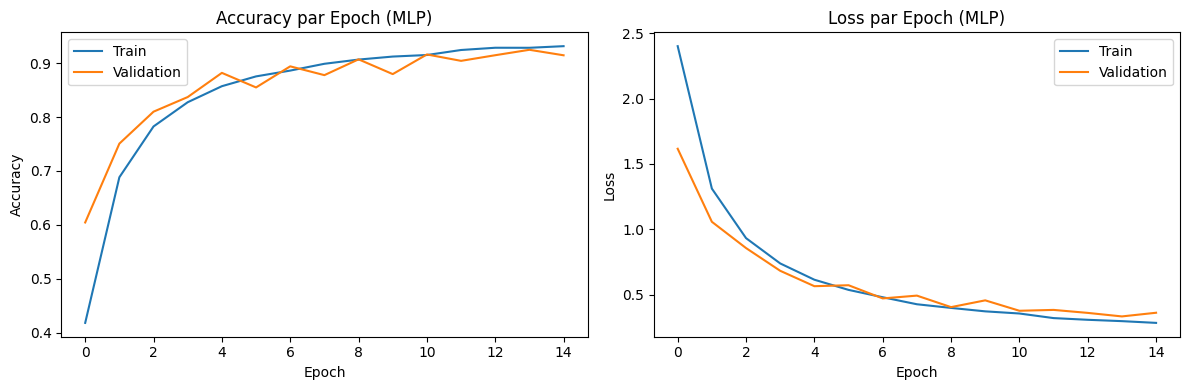

Accuracy sur le Test set (MLP) : 82.38%
Loss sur le Test set (MLP)     : 0.9209


In [10]:
# Visualisation des courbes d'apprentissage et evaluation sur le Test set
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_mlp.history['accuracy'], label='Train')
plt.plot(history_mlp.history['val_accuracy'], label='Validation')
plt.title('Accuracy par Epoch (MLP)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mlp.history['loss'], label='Train')
plt.plot(history_mlp.history['val_loss'], label='Validation')
plt.title('Loss par Epoch (MLP)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Evaluation finale sur les donnees de test
test_loss_mlp, test_acc_mlp = model_mlp.evaluate(X_test, y_test, verbose=0)
print(f"Accuracy sur le Test set (MLP) : {test_acc_mlp * 100:.2f}%")
print(f"Loss sur le Test set (MLP)     : {test_loss_mlp:.4f}")


### Explications théoriques

- **Transformation de l'image :** L'image couleur $32 \times 32 \times 3$ possède 3 072 valeurs de pixels. La couche `Flatten` transforme cette matrice 3D en un vecteur 1D de 3 072 valeurs pour alimenter la couche dense.
- **Rôle des poids ($w$) et des biais ($b$) :** Chaque neurone calcule $z = \sum (w_i \cdot x_i) + b$. Les poids mesurent l'importance relative de chaque pixel et le biais permet d'ajuster le seuil d'activation du neurone.
- **Propagation avant (*Forward pass*) :** Les données circulent de la couche d'entrée vers la sortie, en effectuant les combinaisons linéaires et les activations couche par couche.
- **Fonctions d'activation :**
  - `ReLU` ($f(z) = \max(0, z)$) : introduit de la non-linéarité dans la couche cachée sans saturer les gradients pour les valeurs positives.
  - `Softmax` : sur la dernière couche (43 neurones), transforme les scores bruts en probabilités réelles comprises entre 0 et 1 (dont la somme est égale à 1).
- **Fonction de perte (*Categorical Cross-Entropy*) :** Mesure l'écart entre la distribution de probabilités prédite par le modèle et la vraie classe (One-Hot).
- **Rétropropagation et descente de gradient :** L'erreur calculée en sortie est rétropropagée en arrière pour calculer les gradients par rapport aux poids, et l'optimiseur (Adam) met à jour les poids pour minimiser l'erreur.
- **Limite du modèle dense :** Le réseau dense détruit la disposition spatiale 2D des pixels (formes, contours). Il servira de référence pour montrer l'apport du CNN en Partie 3.


---
## Partie 3 — Construction d’un CNN avec Keras


In [11]:
# Construction du CNN avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

model_cnn = Sequential([
    Input(shape=(32, 32, 3)),
    
    # Premier bloc convolutionnel
    Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    
    # Deuxieme bloc convolutionnel
    Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    
    # Classification dense
    Flatten(),
    Dense(128, activation='relu'),
    Dense(43, activation='softmax')
])

model_cnn.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,979 (1.22 MB)

 Trainable params: 319,979 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

### Tableau récapitulatif des dimensions et des paramètres (couche par couche)

| Couche | Type | Output Shape | Nb Paramètres | Détail du calcul des paramètres |
| :--- | :--- | :---: | :---: | :--- |
| `Input` | Entrée | `(32, 32, 3)` | 0 | Image couleur RGB standardisée |
| `Conv2D_1` | 32 filtres (3x3), ReLU | `(30, 30, 32)` | 896 | $(3 \times 3 \times 3 + 1) \times 32$ |
| `MaxPooling2D_1` | Pooling (2x2) | `(15, 15, 32)` | 0 | Réduction de taille (pas de paramètres) |
| `Conv2D_2` | 64 filtres (3x3), ReLU | `(13, 13, 64)` | 18 496 | $(3 \times 3 \times 32 + 1) \times 64$ |
| `MaxPooling2D_2` | Pooling (2x2) | `(6, 6, 64)` | 0 | Réduction de taille (pas de paramètres) |
| `Flatten` | Aplatissement | `(2304)` | 0 | $6 \times 6 \times 64 = 2\,304$ |
| `Dense_1` | Couche cachée (ReLU) | `(128)` | 295 040 | $(2304 + 1) \times 128$ |
| `Dense_2` | Sortie (Softmax) | `(43)` | 5 547 | $(128 + 1) \times 43$ |
| **Total** | | | **319 979** | Tous entraînables |


### Explications des notions clés demandées

- **Le rôle des filtres :** Chaque filtre est un petit masque de poids appris qui détecte un motif visuel spécifique. Les premiers filtres repèrent des détails élémentaires (bords, lignes, contrastes), et les couches plus profondes combinent ces motifs pour reconnaître des formes plus complexes (formes circulaires de limitation, triangles de danger, symboles).
- **Principe de la convolution (sur image couleur à 3 canaux) :** L'image possède 3 canaux (R, G, B). Chaque filtre de taille $3 \times 3$ possède donc une profondeur de 3 ($3 \times 3 \times 3 = 27$ poids). Il balaie l'image en effectuant la somme pondérée sur les 3 canaux simultanément, puis ajoute un biais $b$.
- **Feature maps (cartes de caractéristiques) :** C'est la matrice 2D résultant du passage d'un filtre sur l'image. Elle met en valeur les zones de l'image où le motif recherché a été détecté. Avec 32 filtres, on obtient 32 feature maps.
- **Taille du kernel ($3 \times 3$) :** Une petite taille de noyau permet de capturer des caractéristiques fines tout en limitant le nombre total de paramètres.
- **Stride (pas) :** Vaut 1 par défaut, le filtre avance d'un pixel à chaque étape pour ne pas perdre d'information spatiale.
- **Padding (`valid`) :** Pas d'ajout de zéros sur les bords de l'image. La dimension diminue donc selon la formule : $W_{out} = W - K + 1$ (ici $32 - 3 + 1 = 30$).
- **Activation ReLU :** $f(z) = \max(0, z)$. Elle introduit de la non-linéarité indispensable et évite la saturation des gradients pour les valeurs positives.
- **Pooling (MaxPooling $2 \times 2$) :** Conserve uniquement la valeur maximale dans chaque fenêtre $2 \times 2$. Cela divise la hauteur et la largeur par 2, ce qui réduit le nombre de calculs et rend le réseau plus robuste aux petites translations du panneau.
- **Flatten :** Transforme le volume 3D de fin de convolution $(6, 6, 64)$ en un vecteur 1D de 2 304 neurones pour alimenter la classification dense.
- **Couches Dense et Sortie :**
  - `Dense(128)` combine l'ensemble des caractéristiques extraites.
  - `Dense(43, activation='softmax')` produit 43 probabilités positives dont la somme vaut 1 pour prédire la classe du panneau.
